## Investigation of visualization of neccessity of error model on SNV calls

Removal of 'errors' / Filtering True SNVs

Filtering True SNVs identified by an adapted version of the error model as described by [Good, et al. 2017](https://pmc.ncbi.nlm.nih.gov/articles/PMC5788700/). Error models uses the temporal structure of the data to distinguish errors for minority variants

**Treating the technical replicates of each donor replicare as individual populations**

Candidate SNVs should fullfil the following criterea:  
- There is at least timepoint with frequency above 1%
- The SNV is not present in the starting virus populations

**for details on the error model see Supplemental methods 1. Quantification of statistical support for identified candidate variants**

## 0. General 

### 0.1. load libraries

In [1]:
import os, pandas as pd, numpy as np, random

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import seaborn as sns

sns.set_theme(style="white", font="Arial")
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})

plt.rcParams['xtick.bottom'] = True
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 12
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True


### 0.2. General variables

In [3]:
donors = [1,2,3,4]
replicates = ["A", "B", "C"]
passages = list(range(0, 110, 10))
tech_reps = [1,2 ]
populations = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C", "4A", "4B", "4C"]
segments = ["1-PB2", "2-PB1", "3-PA", "4-HA", "5-NP", "6-NA", "7-M", "8-NS"]

hours_per_passage = 72 #hours
generation_time = 6 #hours > assumption based on Baccam, et al. 2006

In [4]:
population_cpal = [ "#005fb9", "#58b4e2", "#8ee6ff", "#860041", "#ca0090", "#ff53c0", "#006e00", "#77a908", "#bbe837", "#0000ba", "#5f38ed", "#d49eff" ]


### 0.3. Functions

## 1. Run error model 

running error model from [python script](../scripts/error_model.py) so prepping data and bash file with commands (reproducible)

### 1.1. Prep data


In [5]:
#snv dir should exists and contain SNV calls > if non-existent/empty see Coverage_to_snv_frequency notebook
snv_dir = "../results/snvs"
coverage_dir = "../results/nucleotide_coverage"

error_model_input_dir = "../results/error_model/input"
if not os.path.isdir(error_model_input_dir):
    os.makedirs(error_model_input_dir)

In [6]:
#load snv summary to see what SNVs meet the baseline criteria 
snv_summary = pd.read_csv("../results/snv_summary.csv", keep_default_na=False, na_values=[""]).set_index(["population", "refname", "nucpos", "snv"]).sort_index()

#create overview of non-synonymous SNVs (for convienence)
non_synonymous_dict = {segment:[] for segment in segments}
for i in snv_summary[snv_summary["non_synonymous"]==True].index.droplevel(0):
    non_synonymous_dict[i[0]].append(i[-1])
    
#load trajectories to see assignment 
trajectories = pd.read_csv("../results/snv_trajectories.csv").set_index(["population", "refname", "nucpos", "snv"]).sort_index()

In [7]:
for population in populations:
    for tech_rep in tech_reps:
        # get alllele counts first
        allele_counts = []
        for timepoint in passages[1:]:
            
            snvs= pd.read_csv(os.path.join(snv_dir, f"snvs_P{timepoint}-{population}_{tech_rep}.csv"), keep_default_na=False, na_values=[""]).set_index(['refname', 'nucpos', 'read_base', "snv"])
            counts = snvs[["nuc_count"]].rename(columns={"nuc_count":timepoint})
            
            try:
                allele_counts = pd.concat([allele_counts, counts], axis=1).fillna(0)
            except TypeError:
                allele_counts  = counts
        
        #add timepoint zero
        allele_counts [0] = 0
        allele_counts = allele_counts[[c for c in sorted(allele_counts.columns)]]
        allele_counts.index = allele_counts.index.droplevel(level=3)
        for c in allele_counts.columns:
            allele_counts[c] = allele_counts[c].astype(np.int32)
            
        #need to get actual coverage for depth 
        allele_depths = pd.read_csv(os.path.join(coverage_dir, f"nuc_coverage_stock_{tech_rep}.csv")).set_index(["refname", "nucpos"]).loc[allele_counts.index.droplevel(level=2)].sort_index()
        allele_depths = allele_depths[["coverage"]].rename(columns={"coverage":0})
        for timepoint in passages[1:]:
            coverage_file = os.path.join(coverage_dir, f"nuc_coverage_P{timepoint}-{population}_{tech_rep}.csv")
            coverage_fu = pd.read_csv(coverage_file).set_index(["refname", "nucpos"]).loc[allele_counts.index.droplevel(level=2)].sort_index()
            coverage = coverage_fu[["coverage"]].rename(columns={"coverage":timepoint})
            
            allele_depths = pd.concat([allele_depths, coverage, ], axis=1).fillna(0)
        
        #write error model input files   
        allele_count_file = os.path.join(error_model_input_dir, f"allele_counts_{population}_{tech_rep}.csv")
        depths_file = os.path.join(error_model_input_dir, f"depths_{population}_{tech_rep}.csv")
        allele_counts.sort_index().to_csv(allele_count_file)
        allele_depths.sort_index().to_csv(depths_file)
        

### 1.2. Prep bash

In [8]:
error_model_results_dir = "../results/error_model/pvalues"
if not os.path.isdir(error_model_results_dir):
    os.makedirs(error_model_results_dir)
    
bash_file = "../scripts/bash/error_model_commands.sh"

In [9]:
current_path = os.getcwd()

#change any of these variables to run locally
repo_dir = "~/LTEE-flu" #CHANGE PATH TO ACTUALLY LOCATION OF THE REPO
threads = 1

allele_count_files = list(sorted([os.path.join(error_model_input_dir,f) for f in os.listdir(error_model_input_dir) if "allele" in f]))
with open(bash_file, "w") as fw:
    fw.write("#!/bin/bash\n\n")
    fw.write(f"cd {repo_dir}\n")
    
    for allele_count_file in allele_count_files:
        depth_file = os.path.join(allele_count_file.replace("allele_count", "depth"))
        
        pop = "_".join(allele_count_file.rstrip('.csv').split("/")[-1].split("_")[-2:])
        result_file = pvalue_file = os.path.join(error_model_results_dir, f"{pop}_pvalues.csv")
        
        cmd = ["python", "./scripts/error_model.py", "-d", depth_file.replace("../", "./"), "-a", allele_count_file.replace("../", "./"), "-o",
                result_file, "-t", str(threads), '\n']
        
        fw.write(" ".join(cmd))


##### Need to have run the bash file generated above 
or well error model results directory needs to have files

## 2. Evaluated error model p-value 

### 2.1. get p-value overview

In [10]:
#get depths and allele counts and P VALUE
#NOT SORTING INDEX > IMPORTANT TO MATCH THE CORRECT P-VALUE TO CORRECT 
raw_pvalue_overview = []
for population in populations:
    for tech_rep in tech_reps:
        allele_count_file = os.path.join(error_model_input_dir, f"allele_counts_{population}_{tech_rep}.csv")
        pvalue_file = os.path.join(error_model_results_dir, f"{population}{tech_rep}_pvalues.csv")

        allele_count = pd.read_csv(allele_count_file)
        allele_count["population"] = f"{population}{tech_rep}"
        allele_count = allele_count.set_index(["population", "refname", "nucpos", "read_base"])
        
        depth_file = os.path.join(error_model_input_dir, f"depths_{population}_{tech_rep}.csv") 
        depths = pd.read_csv(depth_file)
        depths["population"] = f"{population}{tech_rep}"
        depths = depths.set_index(["population", "refname", "nucpos",])
        
        pvalues = pd.read_csv(pvalue_file)
        #check if sizes match > THEY SHOULD MATCH
        if not pvalues.shape[0] == allele_count.shape[0] and not pvalues.shape[0] == depths.shape[0]:
            print ("Problem for which I have not written a solution yet")
        #set index of pvalues to match with allele counts > SNVs
        pvalues.index = allele_count.index
        if isinstance(raw_pvalue_overview, list):
            raw_pvalue_overview = pvalues
        else:
            raw_pvalue_overview = pd.concat([raw_pvalue_overview, pvalues])


### 2.2. Multiple hypothesis testing correction via BH-procedure

In [11]:
#remove SNVs not meeting baseline criteria
to_test = []
for (population, refname, nucpos, base) in raw_pvalue_overview.index:
    pop = population[:-1]
    if (pop, refname, nucpos) in [i[:-1] for i in snv_summary.index.tolist()]: 
        if base in snv_summary.loc[(pop, refname, nucpos), "read_base"].to_list():
            to_test.append((population, refname, nucpos, base))
            
pvalue_overview = raw_pvalue_overview.loc[to_test]

In [12]:
##calculate threshold P-value 
FDRs = [0.05, 0.1, 0.15, 0.2,0.25,0.3]
pvalue_thresholds = []
for FDR in FDRs:
    #skipping snvs that are definite error p == 1
    pvalues =[ v for v in pvalue_overview["p-value"].values if v<1]
    total_pvalues = len(pvalues)

    for p in sorted(pvalues, reverse=True):
        if total_pvalues*p/(pvalues<=p).sum() < FDR:
            break
    threshold_pvalue = p
    print (f"threshold p-value with FDR of {FDR}: {threshold_pvalue}")
    pvalue_thresholds.append(threshold_pvalue)

threshold p-value with FDR of 0.05: 9.999000099990002e-05
threshold p-value with FDR of 0.1: 0.0240951809638072
threshold p-value with FDR of 0.15: 0.1145885411458854
threshold p-value with FDR of 0.2: 0.1852814718528147
threshold p-value with FDR of 0.25: 0.241975802419758
threshold p-value with FDR of 0.3: 0.2963703629637036


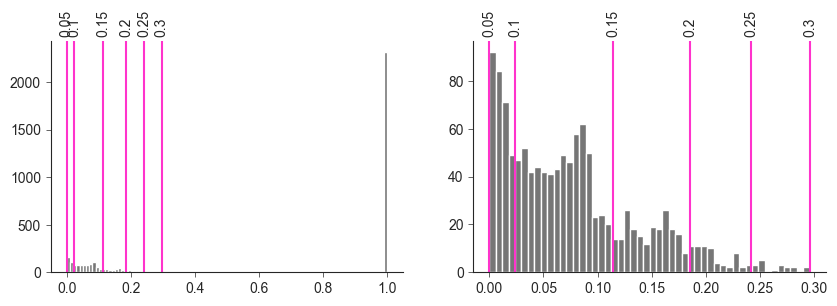

In [13]:
#vizualize p-value distribution
fig, axes = plt.subplots(1, 2, figsize=((10, 3)))
hist = axes[0].hist(pvalue_overview["p-value"].values, bins=100, color="#767676")
hist = axes[1].hist([p for p in pvalue_overview["p-value"].values if p < pvalue_thresholds[-1]], bins=50,  color="#767676")

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    for i, FDR in enumerate(FDRs):
        ax.axvline(pvalue_thresholds[i], color="#FF33CC")
        ax.text(pvalue_thresholds[i],ax.get_ylim()[-1]+(ax.get_ylim()[-1]/50), str(FDR), 
                rotation=90, va="bottom", ha="center", size=10)


In [14]:
#calculate threshold P-value 
FDR = 0.2
pvalues = [p for p in pvalue_overview["p-value"].values if p<1]
total_pvalues = len(pvalues)

for p in sorted(pvalues, reverse=True):
    if total_pvalues*p/(pvalues<=p).sum() < FDR:
        break
threshold_pvalue = p
print (f"threshold p-value with FDR of {FDR}: {threshold_pvalue}")


threshold p-value with FDR of 0.2: 0.1852814718528147


In [15]:
#get accepted pvalue per technical replicate 
accepted_on_pvalues = pvalue_overview[pvalue_overview["p-value"]<threshold_pvalue]
accepted_on_pvalues = accepted_on_pvalues.reset_index()
accepted_on_pvalues["tech_rep"] = [int(p[-1]) for p in accepted_on_pvalues["population"]]
accepted_on_pvalues["population"] = [p[:-1] for p in accepted_on_pvalues["population"]]

accepted_on_pvalues = accepted_on_pvalues.pivot(index=["population", "refname", "nucpos", "read_base"], columns=["tech_rep"], values="p-value")

#pvalue must be accepted in both technical replicates
accepted_on_pvalues = accepted_on_pvalues.dropna()

### 3. Trajectory classification of 
Unpublished experimental work in our lab shows that false-positive SNVs (sequencing or calling errors) do not appear above a frequency of 7%. We therefore treat any SNV observed at a frequency above 10% as a true positive, which leaves a 3-point margin above the observed error ceiling.

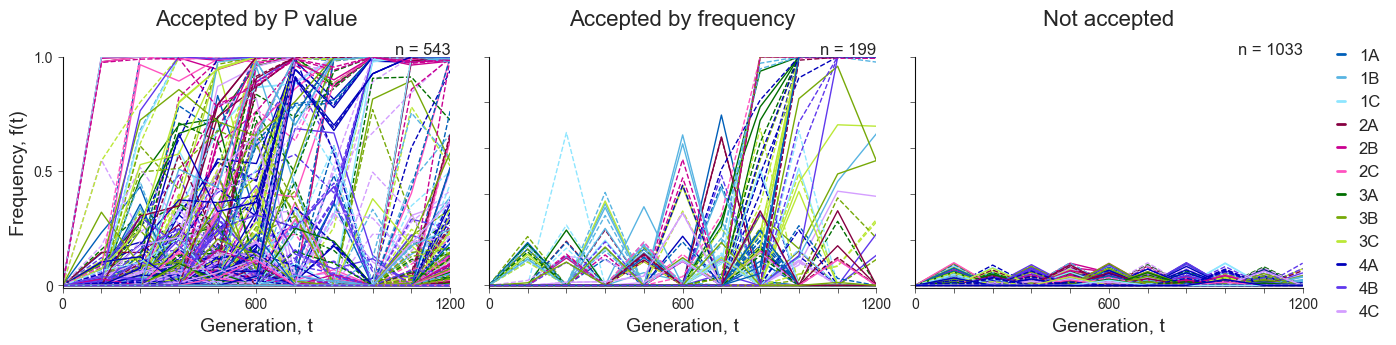

In [16]:

fig, axes = plt.subplots(1,3, figsize=((16,3)))
fig.subplots_adjust(wspace=0.1)

population_legend_elements = []
for i, population in enumerate(populations):
    population_legend_elements.append(Line2D([0], [0], color=population_cpal[i], label=population, linewidth=2,  ))


snv_counter = [0, 0, 0]

#shuffling so trajectories are plotted randomly and not in population order
idx_list = trajectories.index.tolist()
random.shuffle(idx_list)


for (population, refname, nucpos, snv) in idx_list:
    freqs = trajectories.loc[(population, refname, nucpos, snv)].values.tolist()
    max_freq = max(freqs)
    read_base = snv[-1]
    accepted = True if (population, refname, nucpos, read_base) in accepted_on_pvalues.index.tolist() else False
    if accepted:
        axes[0].plot(passages, freqs, c=population_cpal[populations.index(population)], 
                     lw=1, alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        snv_counter[0] +=1 
    elif max_freq >=0.1:
        axes[1].plot(passages, freqs, c=population_cpal[populations.index(population)], 
                     lw=1, alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        snv_counter[1] += 1
    else:
        axes[-1].plot(passages, freqs, c=population_cpal[populations.index(population)], 
                     lw=1, alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        snv_counter[2] += 1
        
for i, ax in enumerate(axes):
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, passages[-1])
    ax.axvline(0, color="black", zorder=100, lw=0.5)

    ax.set_ylim(-0.01,1.0)
    if i ==0:
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_yticklabels([0, 0.5, 1.0], size=10)
        ax.set_ylabel("Frequency, f(t)", size=14)
    else:
        ax.set_yticklabels([])
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
    ax.set_xticklabels([0, "", "", "", "", int((50*hours_per_passage)/generation_time), 
                                "", "", "", "", int((100*hours_per_passage)/generation_time)], size=10)
    ax.set_xlabel("Generation, t", size=14)
    ax.set_title(["Accepted by P value", "Accepted by frequency", "Not accepted"][i], size=16, y=1.1)
    ax.text(100 , 1.0, f"n = {snv_counter[i]}", va="bottom", ha="right", size=12)
                
leg = axes[-1].legend(handles=population_legend_elements, loc='center left', 
                        bbox_to_anchor=(1.05,0.45), ncols =1, fontsize=12, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)   

fig.savefig("../figures/figS3_trajectories_by_error_model.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/figS3_trajectories_by_error_model.png", dpi=300,bbox_inches='tight')  

**Figure S3 The allele frequency trajectories of all de novo single nucleotide variants (SNVs) detected in the experimental populations separate by classified error model acceptance and/or frequency acceptance**. SNV trajectories accepted by frequency have a P-value above 0.05, yet their frequency reached above the acceptance threshold of 10%. SNV trajectories are coloured by populations.